In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns
import json
from PIL import Image as PILImage
import ast
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Leiden-Seed Stability and Agent Repeatability — PBMC3k

## Purpose and design

This notebook has two linked parts, presented in this order:

1. **Fixed-configuration Leiden-seed sensitivity and consensus:** use the configuration selected in Run 6 across the two fixed-Leiden-seed agent batches (`n_neighbors=45`, `n_pcs=10`, `resolution=0.90`) and assess how partitions vary across ten Leiden seeds, followed by consensus clustering.
2. **Agent repeatability:** examine parameter trajectories, internal metrics, and agreement between final-selected partitions across eight agent runs with LLM seed 42 and Leiden seed 42 fixed.

| Setting | Fixed-configuration seed analysis | Agent repeatability |
|---|---|---|
| Dataset | PBMC3k, 2,638 cells | Same dataset and cells |
| LLM | Not used in this stage | GPT-5, configured seed 42, temperature 0 |
| Leiden seed | Varied across ten seeds | Fixed at 42 |
| Parameters | `n_neighbors=45`, `n_pcs=10`, `resolution=0.90` | Adaptively selected by the agent |
| Runs | Ten Leiden-seed runs | Eight agent runs |

The first section assesses sensitivity to Leiden randomness while holding the selected clustering configuration fixed. The later agent section evaluates repeatability under fixed seed settings.

The consensus uses **\(k=9\) as an analysis choice**, not as known ground truth. Consensus clustering summarizes agreement among the resulting partitions and is descriptive rather than independent biological validation.

In [2]:
experiments_dir = Path.cwd() / "experiments"

fixed_dir = (
    experiments_dir
    / "llm_seed42_agent_repeatability_20261018_222712_094535"
    / "new_analysis_k9"
)

analysis_dir = pd.read_csv(
    fixed_dir / "new_final_best_selection_table.csv"
)

# Show all columns and complete cell contents
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

display(analysis_dir)

,experiment_id,run_index,leiden_seed,llm_seed,selected_iteration,selected_parameters,n_clusters,selected_n_neighbors,selected_n_pcs,selected_resolution,selected_silhouette,selected_davies_bouldin,selected_wc_dispersion
0,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,1,42,42,6,"{""n_neighbors"": 20, ""n_pcs"": 25, ""resolution"": 0.6}",8,20,25,0.6,0.229653,1.521914,196028.453125
1,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_02_LSEED_42,2,42,42,15,"{""n_neighbors"": 25, ""n_pcs"": 12, ""resolution"": 1.1}",11,25,12,1.1,0.228929,1.249464,85592.031250
2,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_03_LSEED_42,3,42,42,7,"{""n_neighbors"": 30, ""n_pcs"": 10, ""resolution"": 0.8}",10,30,10,0.8,0.279709,1.138635,67721.726562
3,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_04_LSEED_42,4,42,42,12,"{""n_neighbors"": 20, ""n_pcs"": 40, ""resolution"": 0.5}",7,20,40,0.5,0.196792,1.742738,320380.656250
4,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_05_LSEED_42,5,42,42,8,"{""n_neighbors"": 15, ""n_pcs"": 12, ""resolution"": 0.8}",10,15,12,0.8,0.238647,1.369541,85507.835938
5,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_06_LSEED_42,6,42,42,12,"{""n_neighbors"": 45, ""n_pcs"": 10, ""resolution"": 0.9}",10,45,10,0.9,0.278014,1.140918,67643.296875
6,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_07_LSEED_42,7,42,42,7,"{""n_neighbors"": 30, ""n_pcs"": 30, ""resolution"": 0.7}",8,30,30,0.7,0.207311,1.662412,233163.890625
7,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_08_LSEED_42,8,42,42,7,"{""n_neighbors"": 15, ""n_pcs"": 20, ""resolution"": 0.6}",8,15,20,0.6,0.257866,1.371149,157831.562500


Run 6 was selected because it was the **only run with matching selected parameters across the two fixed-Leiden-seed agent batches**. Both batches selected `n_neighbors=45`, `n_pcs=10`, and `resolution=0.90`, producing ten clusters in each case. This provides a practical, reproducible basis for investigating Leiden-seed sensitivity, but does not establish a globally optimal configuration.

## Fixed-configuration Leiden-seed sensitivity and consensus

Ten Leiden runs use different random seeds while holding preprocessing, the neighborhood graph, and clustering parameters fixed. This tests sensitivity to Leiden initialization conditional on the fixed graph; it does not rerun the LLM agent.

- **Reference configuration:** `n_neighbors=45`, `n_pcs=10`, `resolution=0.90` (*selected in Run 6 across both fixed-Leiden-seed agent batches*)
- **Leiden seeds:** 1, 2, 3, 6, 23, 45, 7, 11, 17, 29
- **Consensus method:** co-association distance \(D=1-C\), followed by average-linkage agglomerative clustering with \(k=9\)

The consensus summarizes the ten partitions. Choosing \(k=9\) is an analysis decision, not evidence that nine is the ground-truth number of populations.

The configuration is treated as a **candidate for stability analysis, not a definitive optimum**. Matching parameter selections and cluster counts do not establish identical cell assignments or biological validity. Likewise, the consensus with \(k=9\) is descriptive and does not establish the true number of biological populations.

### Reproducing the fixed-configuration Leiden experiment

These commands are optional; this notebook reads the saved outputs. Running the first command creates a new timestamped seed-experiment folder. The second script should then point to that folder to build the consensus.

```bash
python 02_01_leiden_seed_reproducibility.py \
  --n-neighbors 45 \
  --n-pcs 10 \
  --resolution 0.90 \
  --seeds 1 2 3 6 23 45 7 11 17 29
```

Then run `02_02_consensus_leiden_seed_runs_10seeds.py` to Build the consensus from the output directory generated by the seed experiment. with `EXPERIMENT_DIR` set to the intended seed-experiment folder. 

**The consensus script loads the saved labels and creates the consensus partition, summaries, and figures.**


### Load and verify saved results

In [3]:
PROJECT_DIR = Path.cwd()

SEED_DIR = (
    PROJECT_DIR
    / "experiments"
    / "leiden_seed_reproducibility_20261019_181654")

CONSENSUS_DIR = (
    PROJECT_DIR
    / "experiments"
    / "leiden_seed_consensus_k9_20261019_182059")

print("\n--- Ten-seed experiment files ---")
for path in sorted(SEED_DIR.iterdir()):
    print(path.name)

print("\n--- Consensus experiment files ---")
for path in sorted(CONSENSUS_DIR.iterdir()):
    print(path.name)


--- Ten-seed experiment files ---
cluster_sizes.csv
figures
labels
leiden_seed_summary.csv
pairwise_ari.csv
pairwise_nmi.csv
run_summary.json

--- Consensus experiment files ---
coassociation_matrix.npy
consensus_cluster_sizes.csv
consensus_labels.csv
consensus_labels.npy
consensus_summary.json
consensus_vs_seed_partitions.csv
fig1_coassociation_heatmap.png
fig2_pairwise_ari_heatmap.png
fig3_pairwise_nmi_heatmap.png
fig4_consensus_agreement.png
fig5_consensus_umap.png
pairwise_seed_similarity.csv


Load saved summaries for the ten-seed experiment and consensus analysis. This does not rerun either experiment.


In [4]:
# Load concise saved summaries
with open(SEED_DIR / "run_summary.json", "r") as f:
    run_summary = json.load(f)
with open(CONSENSUS_DIR / "consensus_summary.json", "r") as f:
    consensus_summary = json.load(f)

for field in ["experiment", "created_at_utc", "n_cells", "n_genes_after_preprocessing"]:
    print(f"{field}: {run_summary.get(field, 'Not available')}")
# print("\nConsensus summary:")
# print(json.dumps(consensus_summary, indent=2))


experiment: Leiden-seed reproducibility with fixed graph
created_at_utc: 2026-10-19T16:17:04.653736+00:00
n_cells: 2638
n_genes_after_preprocessing: 2000


### Clustering Metrics Across Leiden Seeds
The table summarizes clustering quality and cluster-size characteristics across ten Leiden seeds, with the graph and clustering parameters held fixed.

In [5]:
METRICS_FILE = "leiden_seed_summary.csv"

metrics = pd.read_csv(SEED_DIR / METRICS_FILE)
display(metrics)

,seed,n_cells,n_clusters,silhouette_score,davies_bouldin_index,largest_cluster_cells,largest_cluster_fraction_pct,clusters_under_30_cells,cells_in_clusters_under_30,labels_file
0,1,2638,10,0.273019,1.193574,553,20.962851,1,13,labels/seed_1_labels.npy
1,2,2638,10,0.251565,1.322278,483,18.309325,1,13,labels/seed_2_labels.npy
2,3,2638,10,0.250306,1.299087,483,18.309325,1,13,labels/seed_3_labels.npy
3,6,2638,10,0.269285,1.205766,589,22.327521,1,13,labels/seed_6_labels.npy
4,23,2638,9,0.259446,1.482705,477,18.081880,0,0,labels/seed_23_labels.npy
5,45,2638,10,0.279068,1.123812,551,20.887036,1,13,labels/seed_45_labels.npy
6,7,2638,10,0.260376,1.320437,477,18.081880,1,13,labels/seed_7_labels.npy
7,11,2638,10,0.266669,1.201756,566,21.455648,1,13,labels/seed_11_labels.npy
8,17,2638,10,0.251525,1.327072,469,17.778620,1,13,labels/seed_17_labels.npy
9,29,2638,9,0.290629,1.138379,632,23.957544,1,13,labels/seed_29_labels.npy


### Internal metrics across Leiden seeds Plot

Compare cluster counts, silhouette scores, and Davies–Bouldin indices across seeds. Higher silhouette and lower DBI generally indicate better internal separation; neither metric establishes biological correctness.

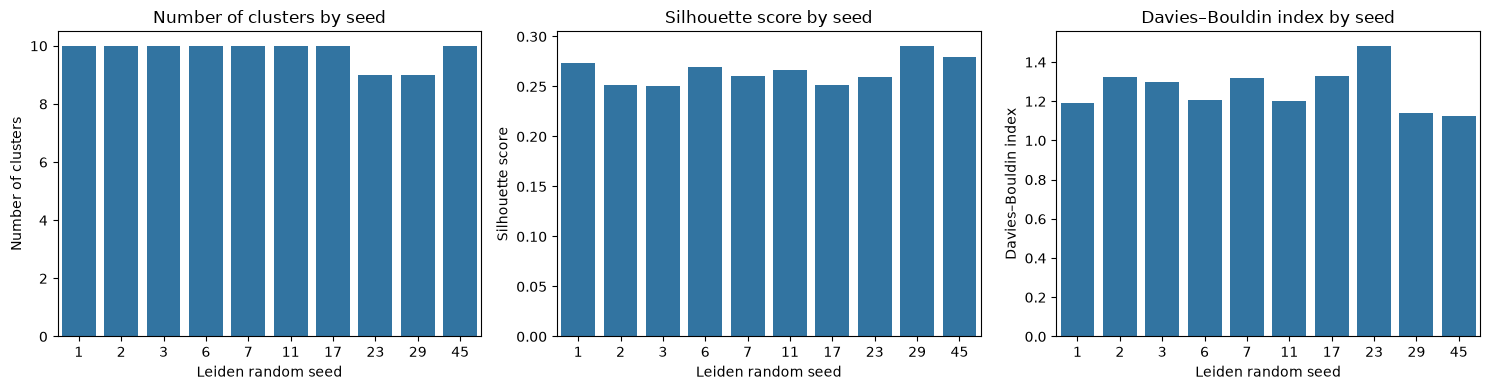

In [6]:

# Column names from leiden_seed_summary.csv
SEED_COL = "seed"
CLUSTER_COL = "n_clusters"
SIL_COL = "silhouette_score"
DBI_COL = "davies_bouldin_index"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=metrics, x=SEED_COL, y=CLUSTER_COL, ax=axes[0])
axes[0].set_title("Number of clusters by seed")
axes[0].set_xlabel("Leiden random seed")
axes[0].set_ylabel("Number of clusters")

sns.barplot(data=metrics, x=SEED_COL, y=SIL_COL, ax=axes[1])
axes[1].set_title("Silhouette score by seed")
axes[1].set_xlabel("Leiden random seed")
axes[1].set_ylabel("Silhouette score")

sns.barplot(data=metrics, x=SEED_COL, y=DBI_COL, ax=axes[2])
axes[2].set_title("Davies–Bouldin index by seed")
axes[2].set_xlabel("Leiden random seed")
axes[2].set_ylabel("Davies–Bouldin index")

plt.tight_layout()
plt.show()


### Pairwise ARI and NMI across Leiden seeds

These heatmaps compare the partitions produced by the ten seeds. Lower values indicate less agreement between the corresponding partitions; they do not by themselves identify which partition is biologically preferable.


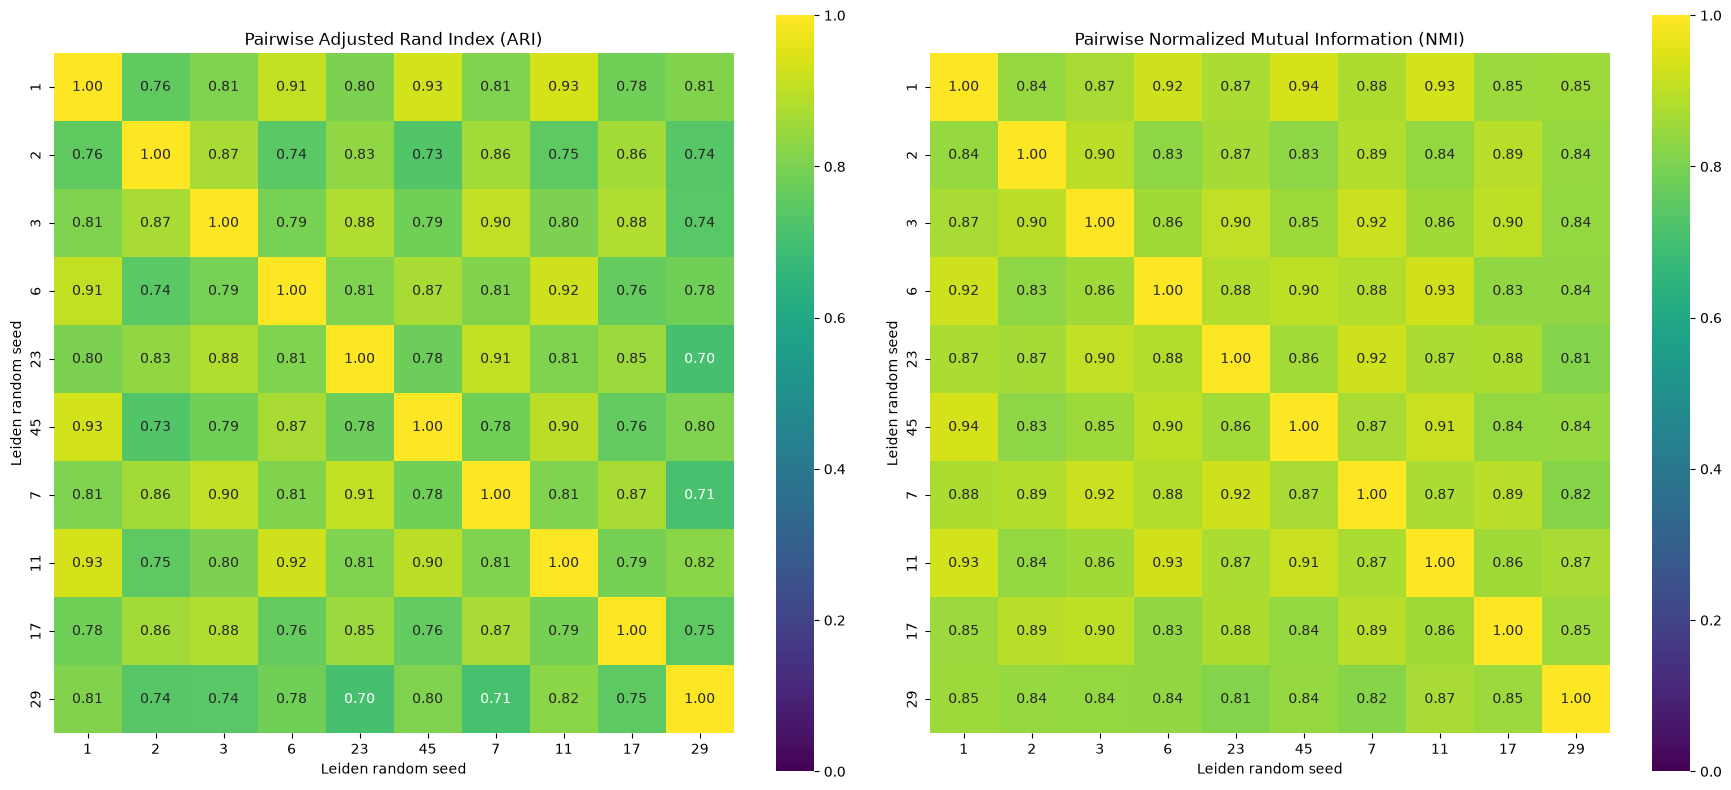

In [7]:
# Exact filenames from your Step 5 output
ARI_FILE = "pairwise_ari.csv"
NMI_FILE = "pairwise_nmi.csv"

def load_similarity_matrix(path):
    df = pd.read_csv(path, index_col=0)
    df.index = df.index.astype(str)
    df.columns = df.columns.astype(str)
    return df.astype(float)

ari_matrix = load_similarity_matrix(SEED_DIR / ARI_FILE)
nmi_matrix = load_similarity_matrix(SEED_DIR / NMI_FILE)

# Keep the ten seeds in the intended order
seed_order = ["1", "2", "3", "6", "23", "45", "7", "11", "17", "29"]

ari_matrix = ari_matrix.loc[seed_order, seed_order]
nmi_matrix = nmi_matrix.loc[seed_order, seed_order]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.heatmap(
    ari_matrix,
    annot=True,
    fmt=".2f",
    vmin=0,
    vmax=1,
    cmap="viridis",
    square=True,
    ax=axes[0]
)
axes[0].set_title("Pairwise Adjusted Rand Index (ARI)")
axes[0].set_xlabel("Leiden random seed")
axes[0].set_ylabel("Leiden random seed")

sns.heatmap(
    nmi_matrix,
    annot=True,
    fmt=".2f",
    vmin=0,
    vmax=1,
    cmap="viridis",
    square=True,
    ax=axes[1]
)
axes[1].set_title("Pairwise Normalized Mutual Information (NMI)")
axes[1].set_xlabel("Leiden random seed")
axes[1].set_ylabel("Leiden random seed")

plt.tight_layout()
plt.show()

**Pairwise ARI and NMI.** Across the ten Leiden seeds, pairwise ARI ranged from 0.70 to 0.93, while NMI ranged from 0.81 to 0.94, indicating substantial but imperfect agreement between partitions. Seeds 1 and 45 showed the strongest agreement (ARI = 0.93; NMI = 0.94), whereas seeds 23 and 29 showed the lowest ARI (0.70). Overall, the results indicate that the fixed configuration retains considerable shared clustering structure across seeds, although partition assignments remain sensitive to the Leiden random seed. ARI and NMI provide complementary measures of partition agreement and are interpreted separately.

## Consensus clustering

The co-association matrix records the fraction of runs in which each pair of cells was assigned to the same cluster. The consensus analysis converts co-association to distance using \(D=1-C\), then applies average-linkage agglomerative clustering with \(k=9\). This provides a summary partition of the ten runs, not independent validation.


### Consensus cluster sizes

Inspect the saved cluster sizes for imbalances or small groups. Small clusters are descriptive findings and should not automatically be interpreted as distinct biological populations.


In [8]:
# Load the saved consensus cluster sizes
CONSENSUS_SIZES_FILE = "consensus_cluster_sizes.csv"

cluster_sizes = pd.read_csv(CONSENSUS_DIR / CONSENSUS_SIZES_FILE)

# Use the saved cell counts and percentages
cluster_sizes = cluster_sizes.sort_values("consensus_cluster").reset_index(drop=True)

display(cluster_sizes)

,consensus_cluster,cell_count,cell_fraction,cell_percentage
0,0,798,0.302502,30.250190
1,1,287,0.108795,10.879454
2,2,367,0.139121,13.912055
3,3,159,0.060273,6.027293
4,4,483,0.183093,18.309325
5,5,344,0.130402,13.040182
6,6,155,0.058757,5.875663
7,7,13,0.004928,0.492798
8,8,32,0.012130,1.213040


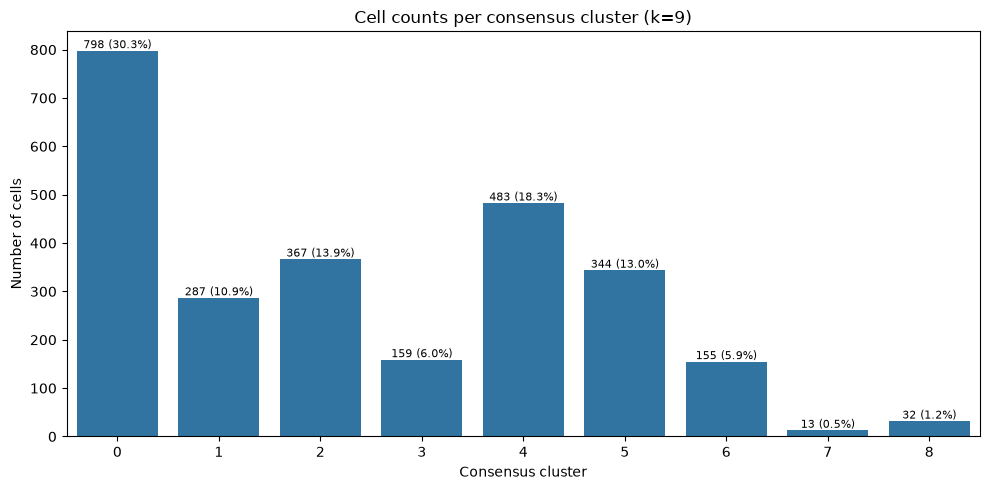

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=cluster_sizes,
    x="consensus_cluster",
    y="cell_count",
    ax=ax
)

ax.set_title(
    f"Cell counts per consensus cluster (k={cluster_sizes['consensus_cluster'].nunique()})"
)
ax.set_xlabel("Consensus cluster")
ax.set_ylabel("Number of cells")

for i, row in cluster_sizes.iterrows():
    ax.text(
        i,
        row["cell_count"] + 5,
        f"{int(row['cell_count'])} ({row['cell_percentage']:.1f}%)",
        ha="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()


### Supplementary consensus visualizations

The co-association heatmap displays pairwise co-clustering frequencies for a sample of 250 cells, ordered by their consensus cluster assignments, to make the structure easier to visualize. The underlying consensus analysis, however uses all 2,638 cells; the 250-cell limit applies only to the heatmap visualization. The consensus UMAP displays the resulting consensus assignments across the dataset. Both plots are descriptive and help illustrate clustering structure and consistency, but do not independently establish biological validity or quantify the stability of every cell assignment.

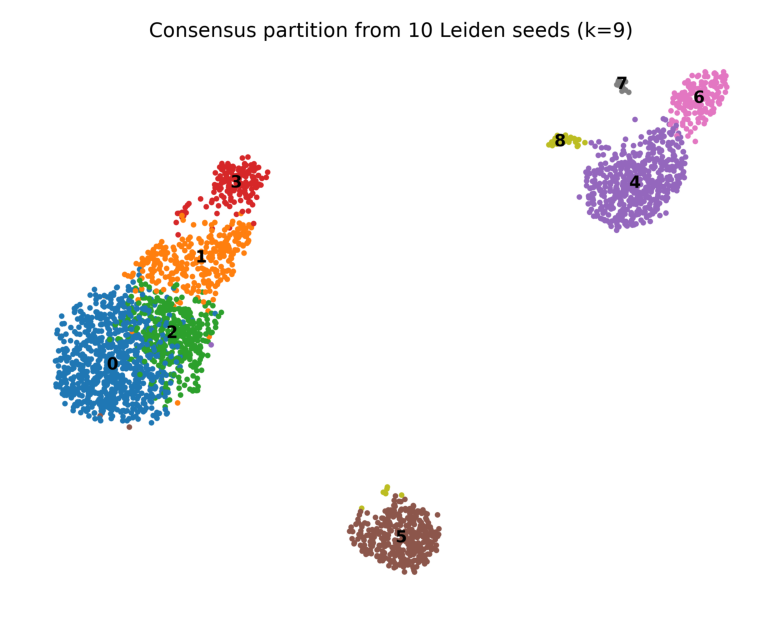

In [10]:
FIGURE_DIR = CONSENSUS_DIR

saved_figures = {
    "Co-association heatmap": "fig1_coassociation_heatmap.png",
    "Pairwise ARI heatmap": "fig2_pairwise_ari_heatmap.png",
    "Pairwise NMI heatmap": "fig3_pairwise_nmi_heatmap.png",
    "Consensus agreement": "fig4_consensus_agreement.png",
    "Consensus UMAP": "fig5_consensus_umap.png",
}

def show_figure(name, width=9):
    path = FIGURE_DIR / saved_figures[name]

    if not path.exists():
        print(f"Figure not found: {path}")
        return

    with PILImage.open(path) as img:
        aspect_ratio = img.height / img.width

        fig, ax = plt.subplots(
            figsize=(width, width * aspect_ratio)
        )
        ax.imshow(img)
        ax.axis("off")
        plt.tight_layout()
        plt.show()


# Display the consensus UMAP at a smaller size
show_figure("Consensus UMAP", width=8)



#### sampled co-association heatmap

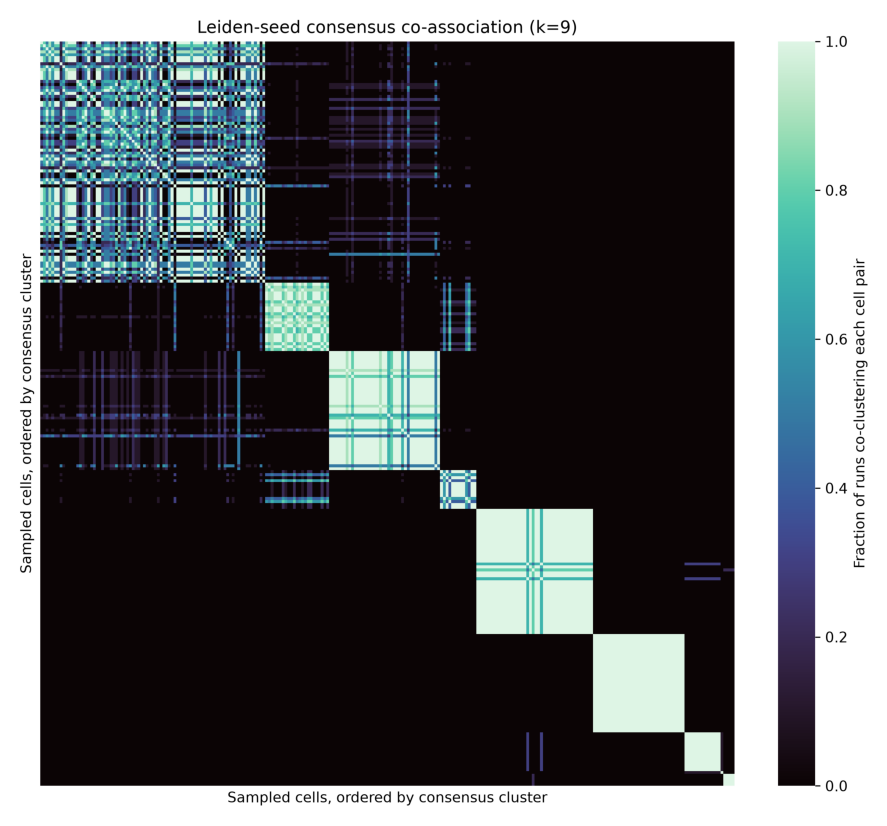

In [11]:
show_figure("Co-association heatmap")

# Agent repeatability: trajectories and selected partitions

The following analyses return to the eight fixed-seed agent runs. They describe the agent's search trajectories, metric variation, and agreement between selected partitions; they are separate from the fixed-configuration Leiden-seed experiment above.

# Load and inspect results

Load CSV outputs. saved experiment and analysis directories

In [12]:
# Paths to the fixed-seed agent analysis
project_dir = Path.cwd()
batch_a_analysis_dir = (
    project_dir / "experiments"
    / "llm_seed42_agent_repeatability_20261018_222712_094535"
    / "new_analysis_k9"
)


### Iteration trajectory overview


In [13]:
# Number of evaluations completed in each agent run
all_iteration_df = pd.read_csv(
    batch_a_analysis_dir / "new_iteration_trajectory_table.csv"
)
iteration_counts = (
    all_iteration_df.groupby(["run_index", "leiden_seed", "llm_seed"])
    .agg(
        n_evaluations=("iteration", "nunique"),
        first_iteration=("iteration", "min"),
        last_iteration=("iteration", "max"),
    )
    .reset_index()
)
display(iteration_counts)


,run_index,leiden_seed,llm_seed,n_evaluations,first_iteration,last_iteration
0,1,42,42,8,0,7
1,2,42,42,16,0,15
2,3,42,42,11,0,10
3,4,42,42,15,0,14
4,5,42,42,13,0,12
5,6,42,42,16,0,15
6,7,42,42,8,0,7
7,8,42,42,12,0,11


The experiment allowed up to 16 evaluations per run. Some runs used up the whole budget while some didn't


### Parameter Trajectories

new_fig_parameter_trajectories.png


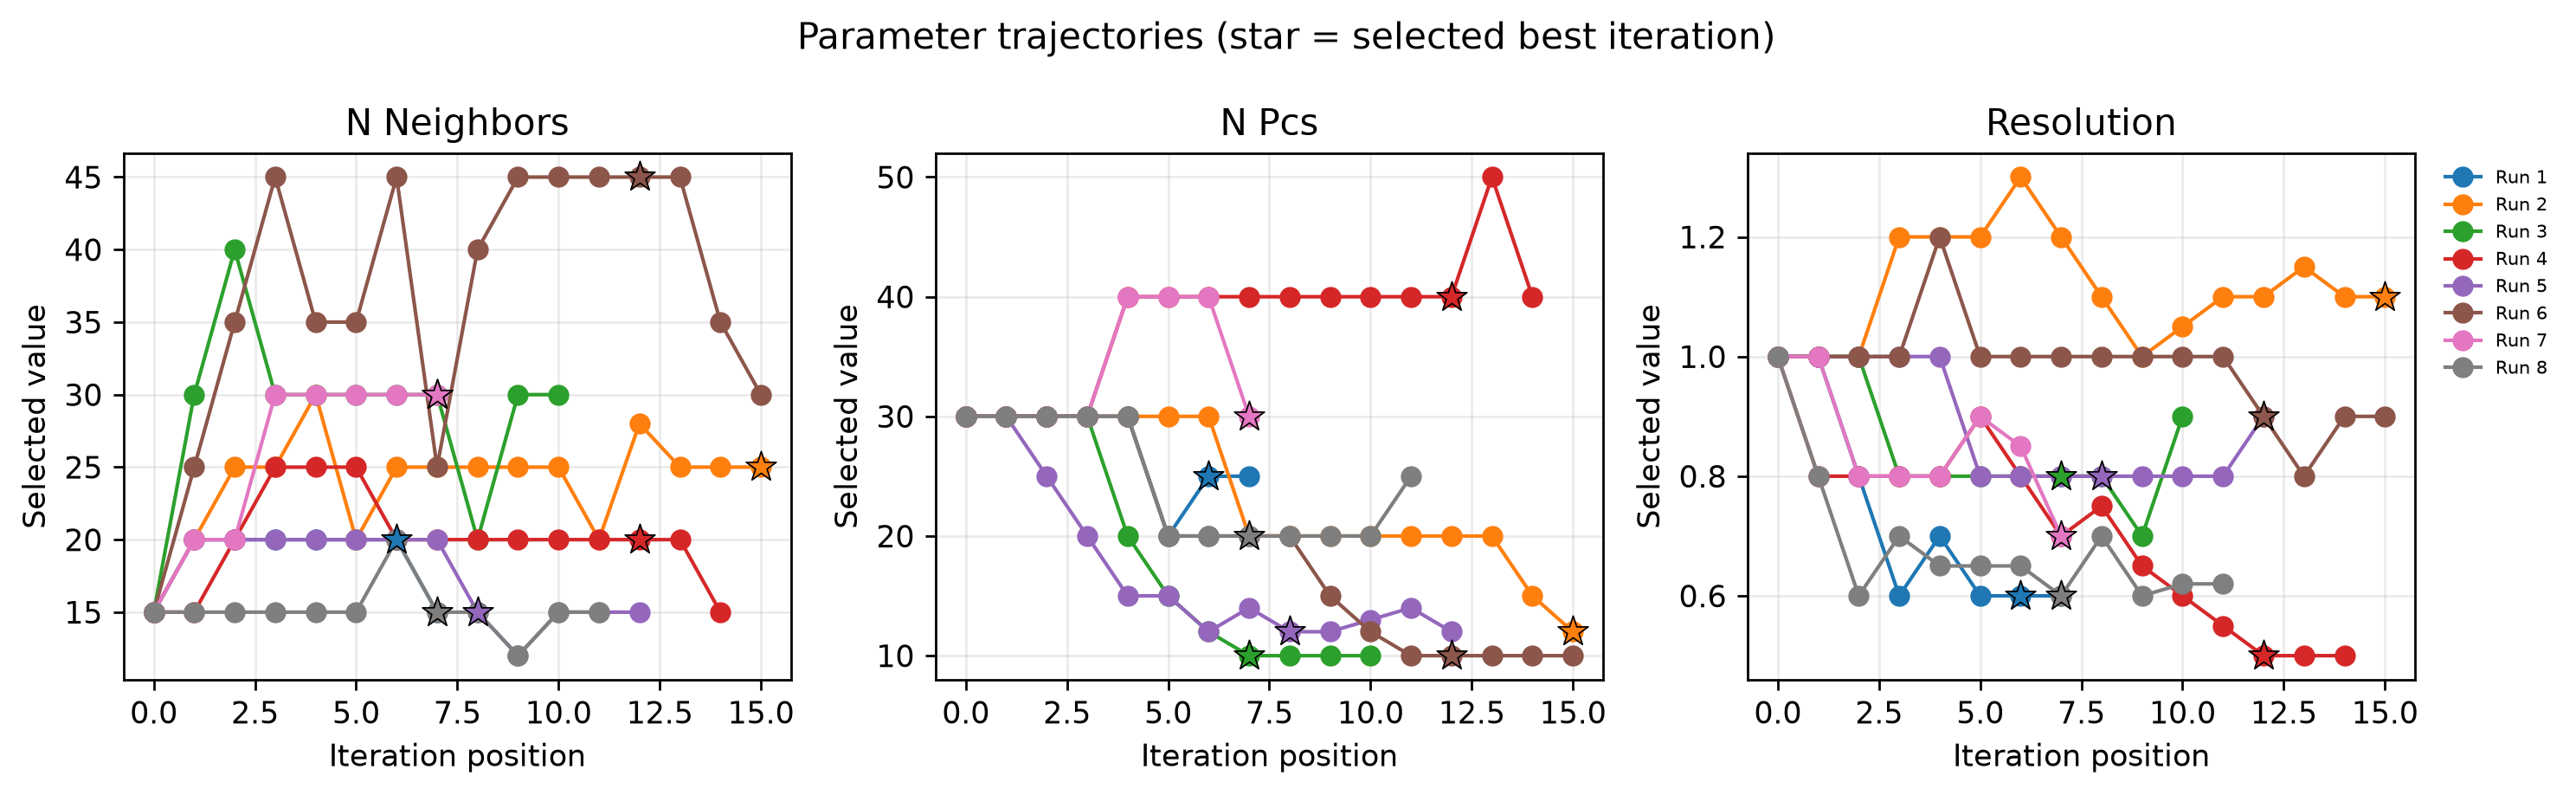

In [14]:
filename = "new_fig_parameter_trajectories.png"
path = batch_a_analysis_dir / filename
print(filename)
display(Image(filename=str(path)))

Stars in the parameter-trajectory plot mark each run's **final-selected iteration**; they do not indicate the optimum for every individual metric. The LLM seed and Leiden seed were both fixed at 42.


### Metrics Trajectories

new_fig_metric_trajectories.png


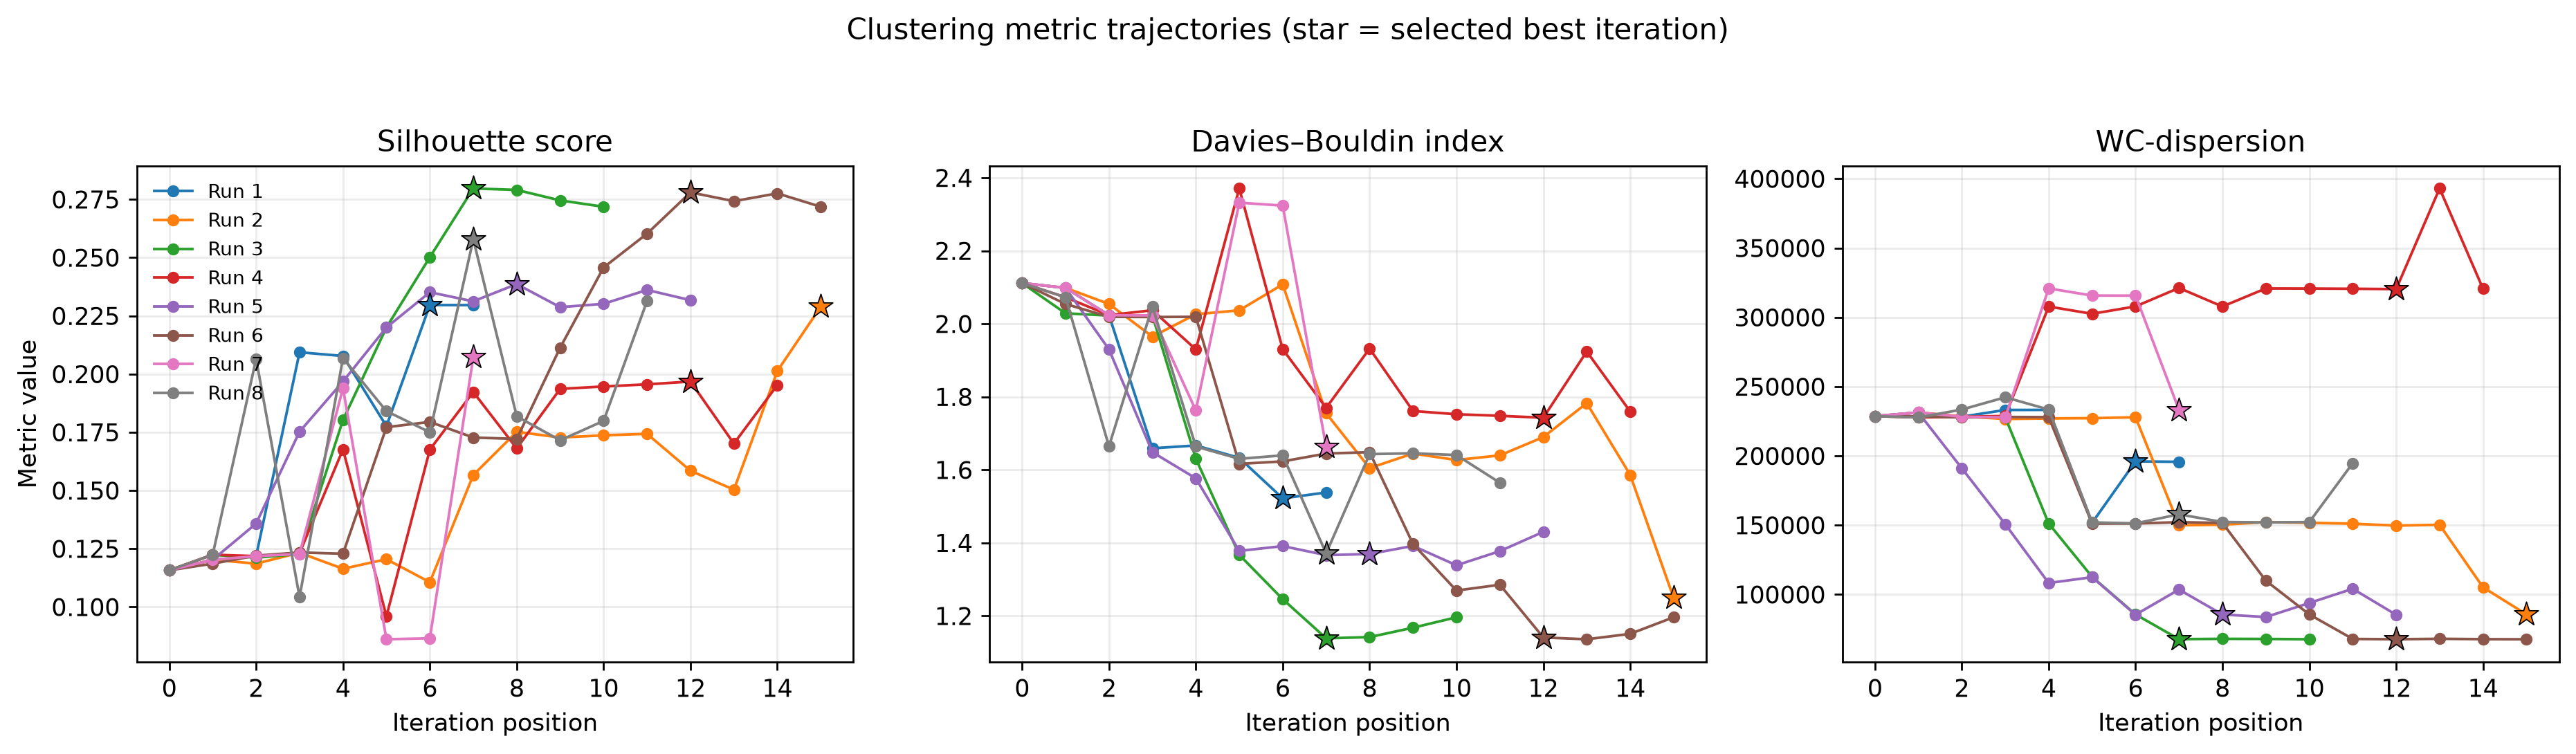

In [15]:
metric_filename = "new_fig_metric_trajectories.png"
path = batch_a_analysis_dir / metric_filename
print(metric_filename)
display(Image(filename=str(path)))

The eight runs followed different parameter-search trajectories, exploring different values of n_neighbors, n_pcs, and resolution. The selected iterations (stars) showed variation in clustering metrics, indicating that no single run consistently achieved the best values across all metrics. 

## Agreement between final-selected agent partitions

Pairwise ARI and NMI compare the final-selected partitions across the eight runs without requiring identical numeric cluster labels. Values closer to 1 indicate stronger partition agreement.


#### 1. Inspect Pairwise Similarity Results

In [16]:
pairwise_df = pd.read_csv(
    batch_a_analysis_dir / "new_final_best_pairwise_similarity.csv"
)

display(pairwise_df.head(10))

,experiment_id_a,leiden_seed_a,experiment_id_b,leiden_seed_b,ari,nmi
0,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_02_LSEED_42,42,0.614581,0.803821
1,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_03_LSEED_42,42,0.626606,0.822925
2,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_04_LSEED_42,42,0.928699,0.917912
3,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_05_LSEED_42,42,0.591846,0.808301
4,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_06_LSEED_42,42,0.632074,0.822391
5,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_07_LSEED_42,42,0.977542,0.959990
6,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_01_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_08_LSEED_42,42,0.951964,0.923575
7,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_02_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_03_LSEED_42,42,0.788221,0.851187
8,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_02_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_04_LSEED_42,42,0.570573,0.775047
9,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_02_LSEED_42,42,llm_seed42_agent_repeatability_20261018_222712_094535_PBMC3k_AGENT_BIOLOGY_REPEAT_05_LSEED_42,42,0.874646,0.896998


#### Pairwise ARI and NMI

These heatmaps summarize agreement between final-selected partitions. Cluster labels are arbitrary, so ARI and NMI compare cell assignments rather than label names.


new_fig_final_best_ari_heatmap.png


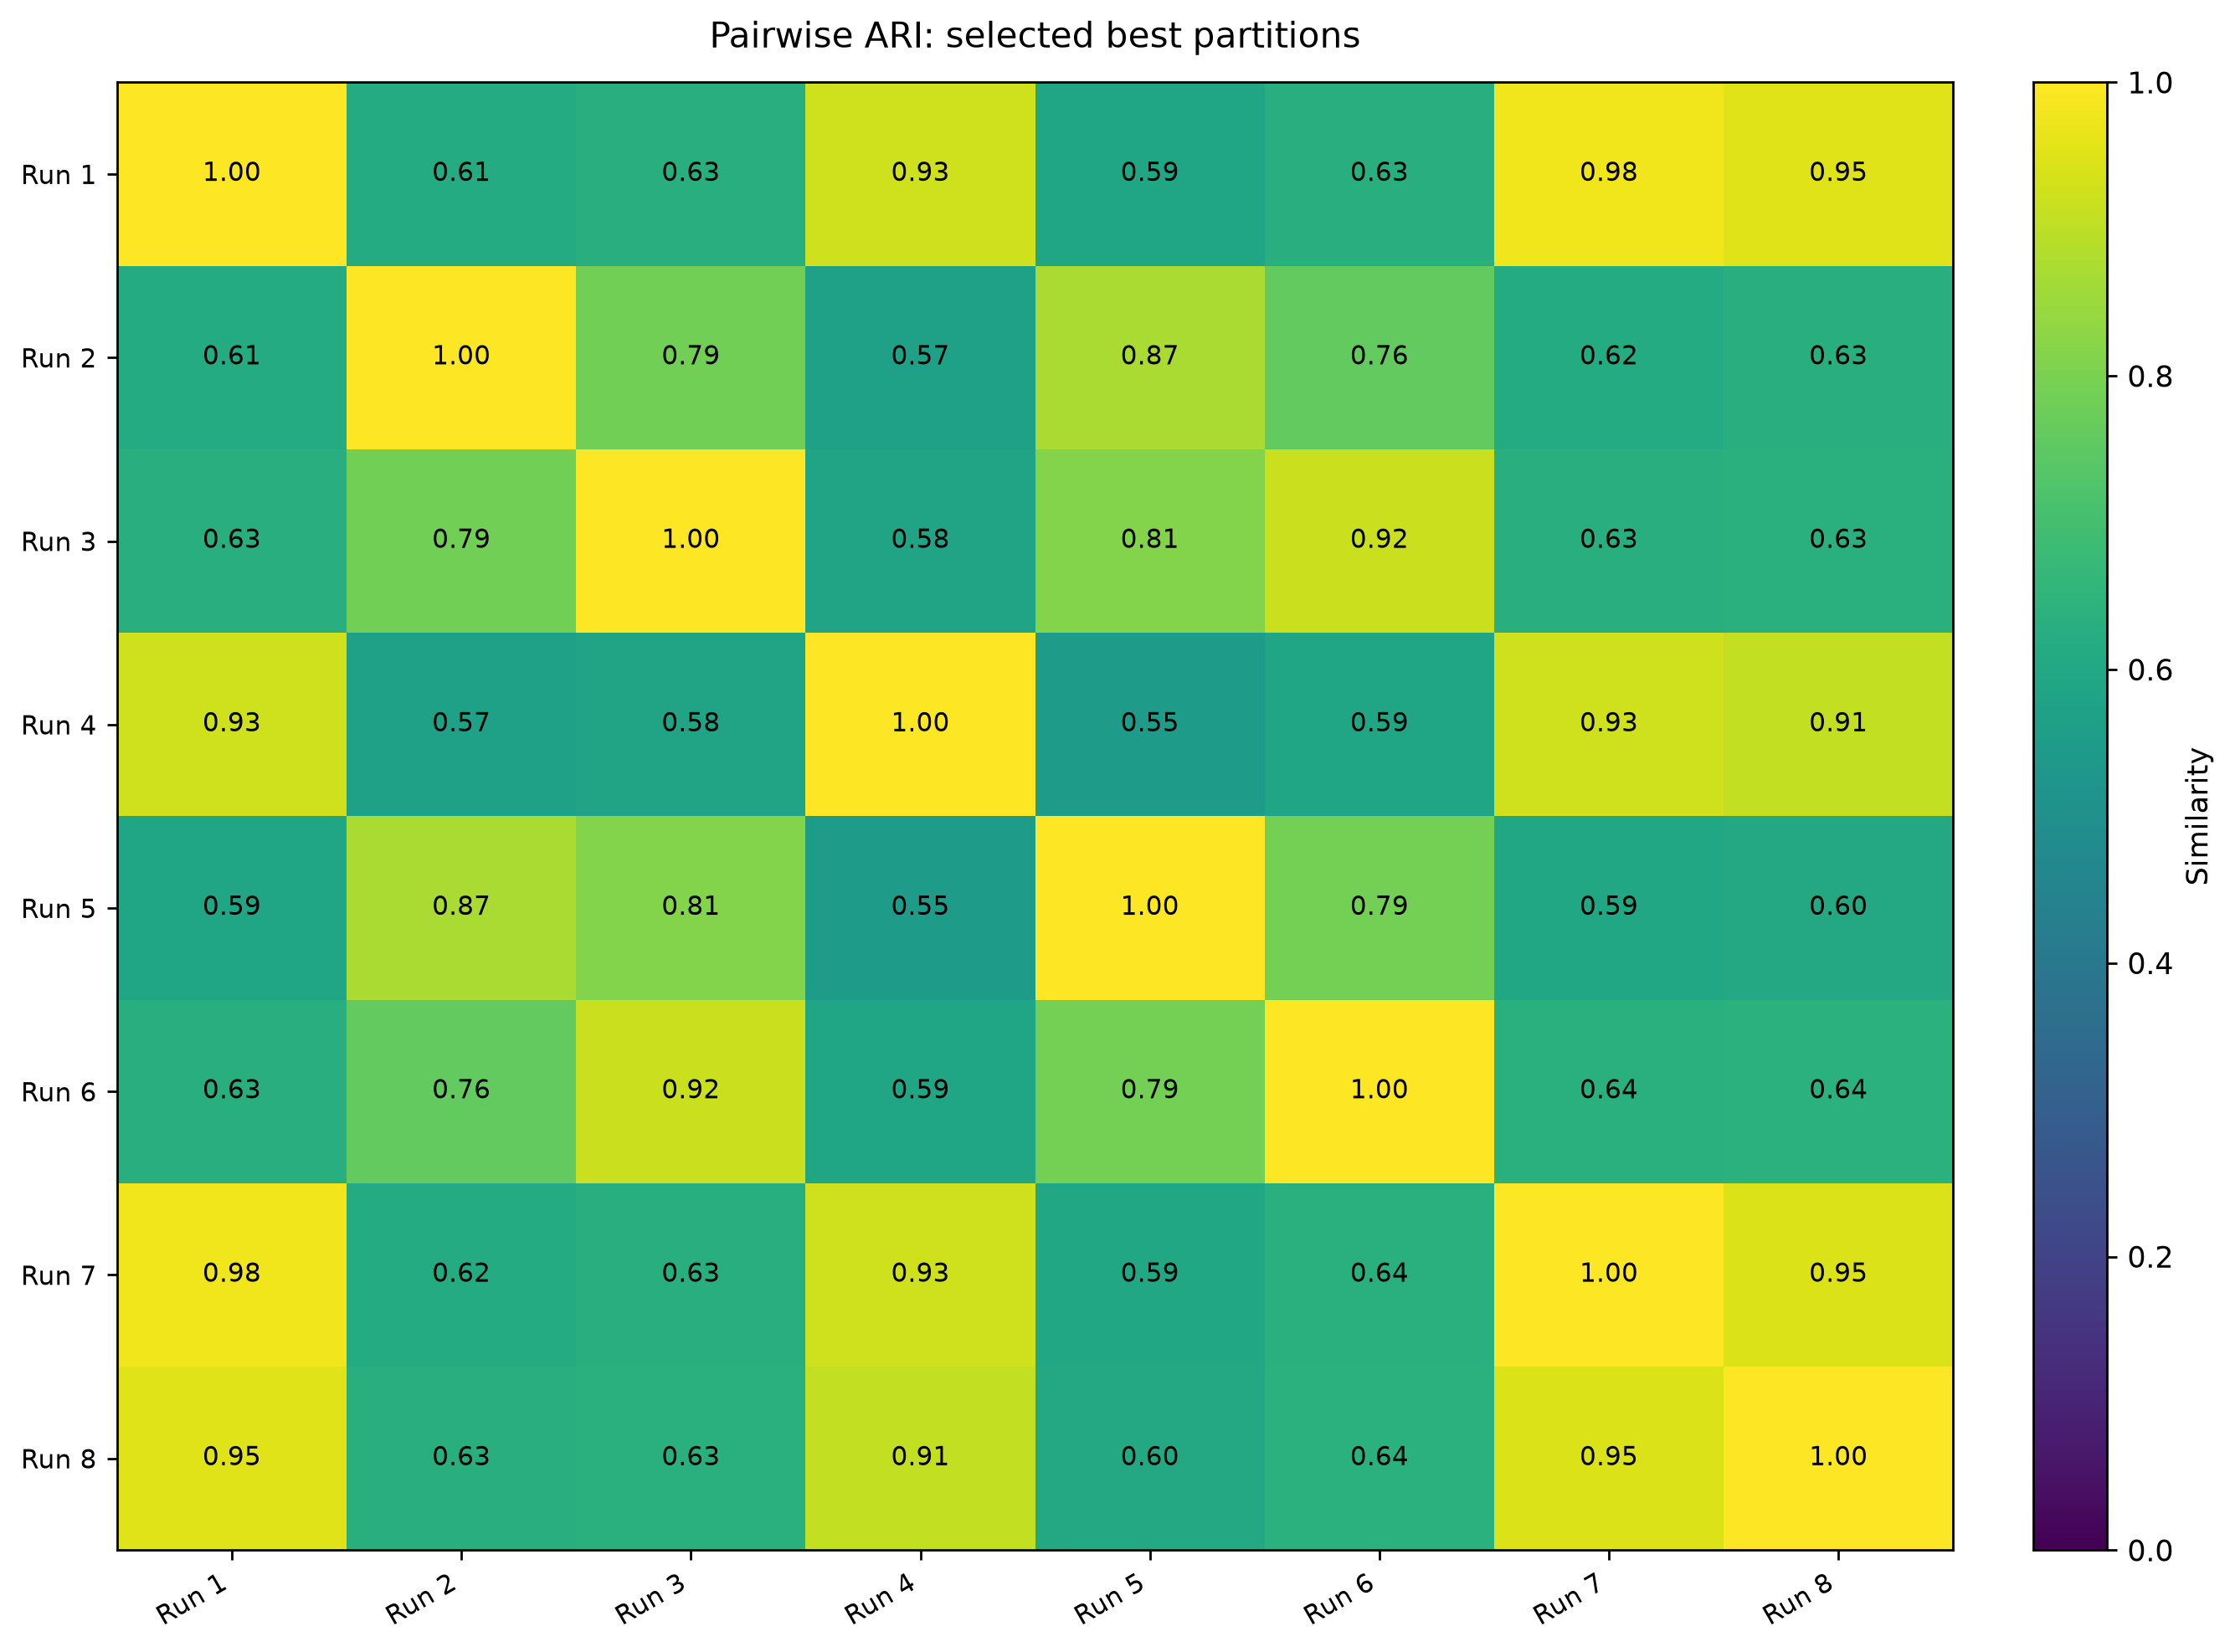

new_fig_final_best_nmi_heatmap.png


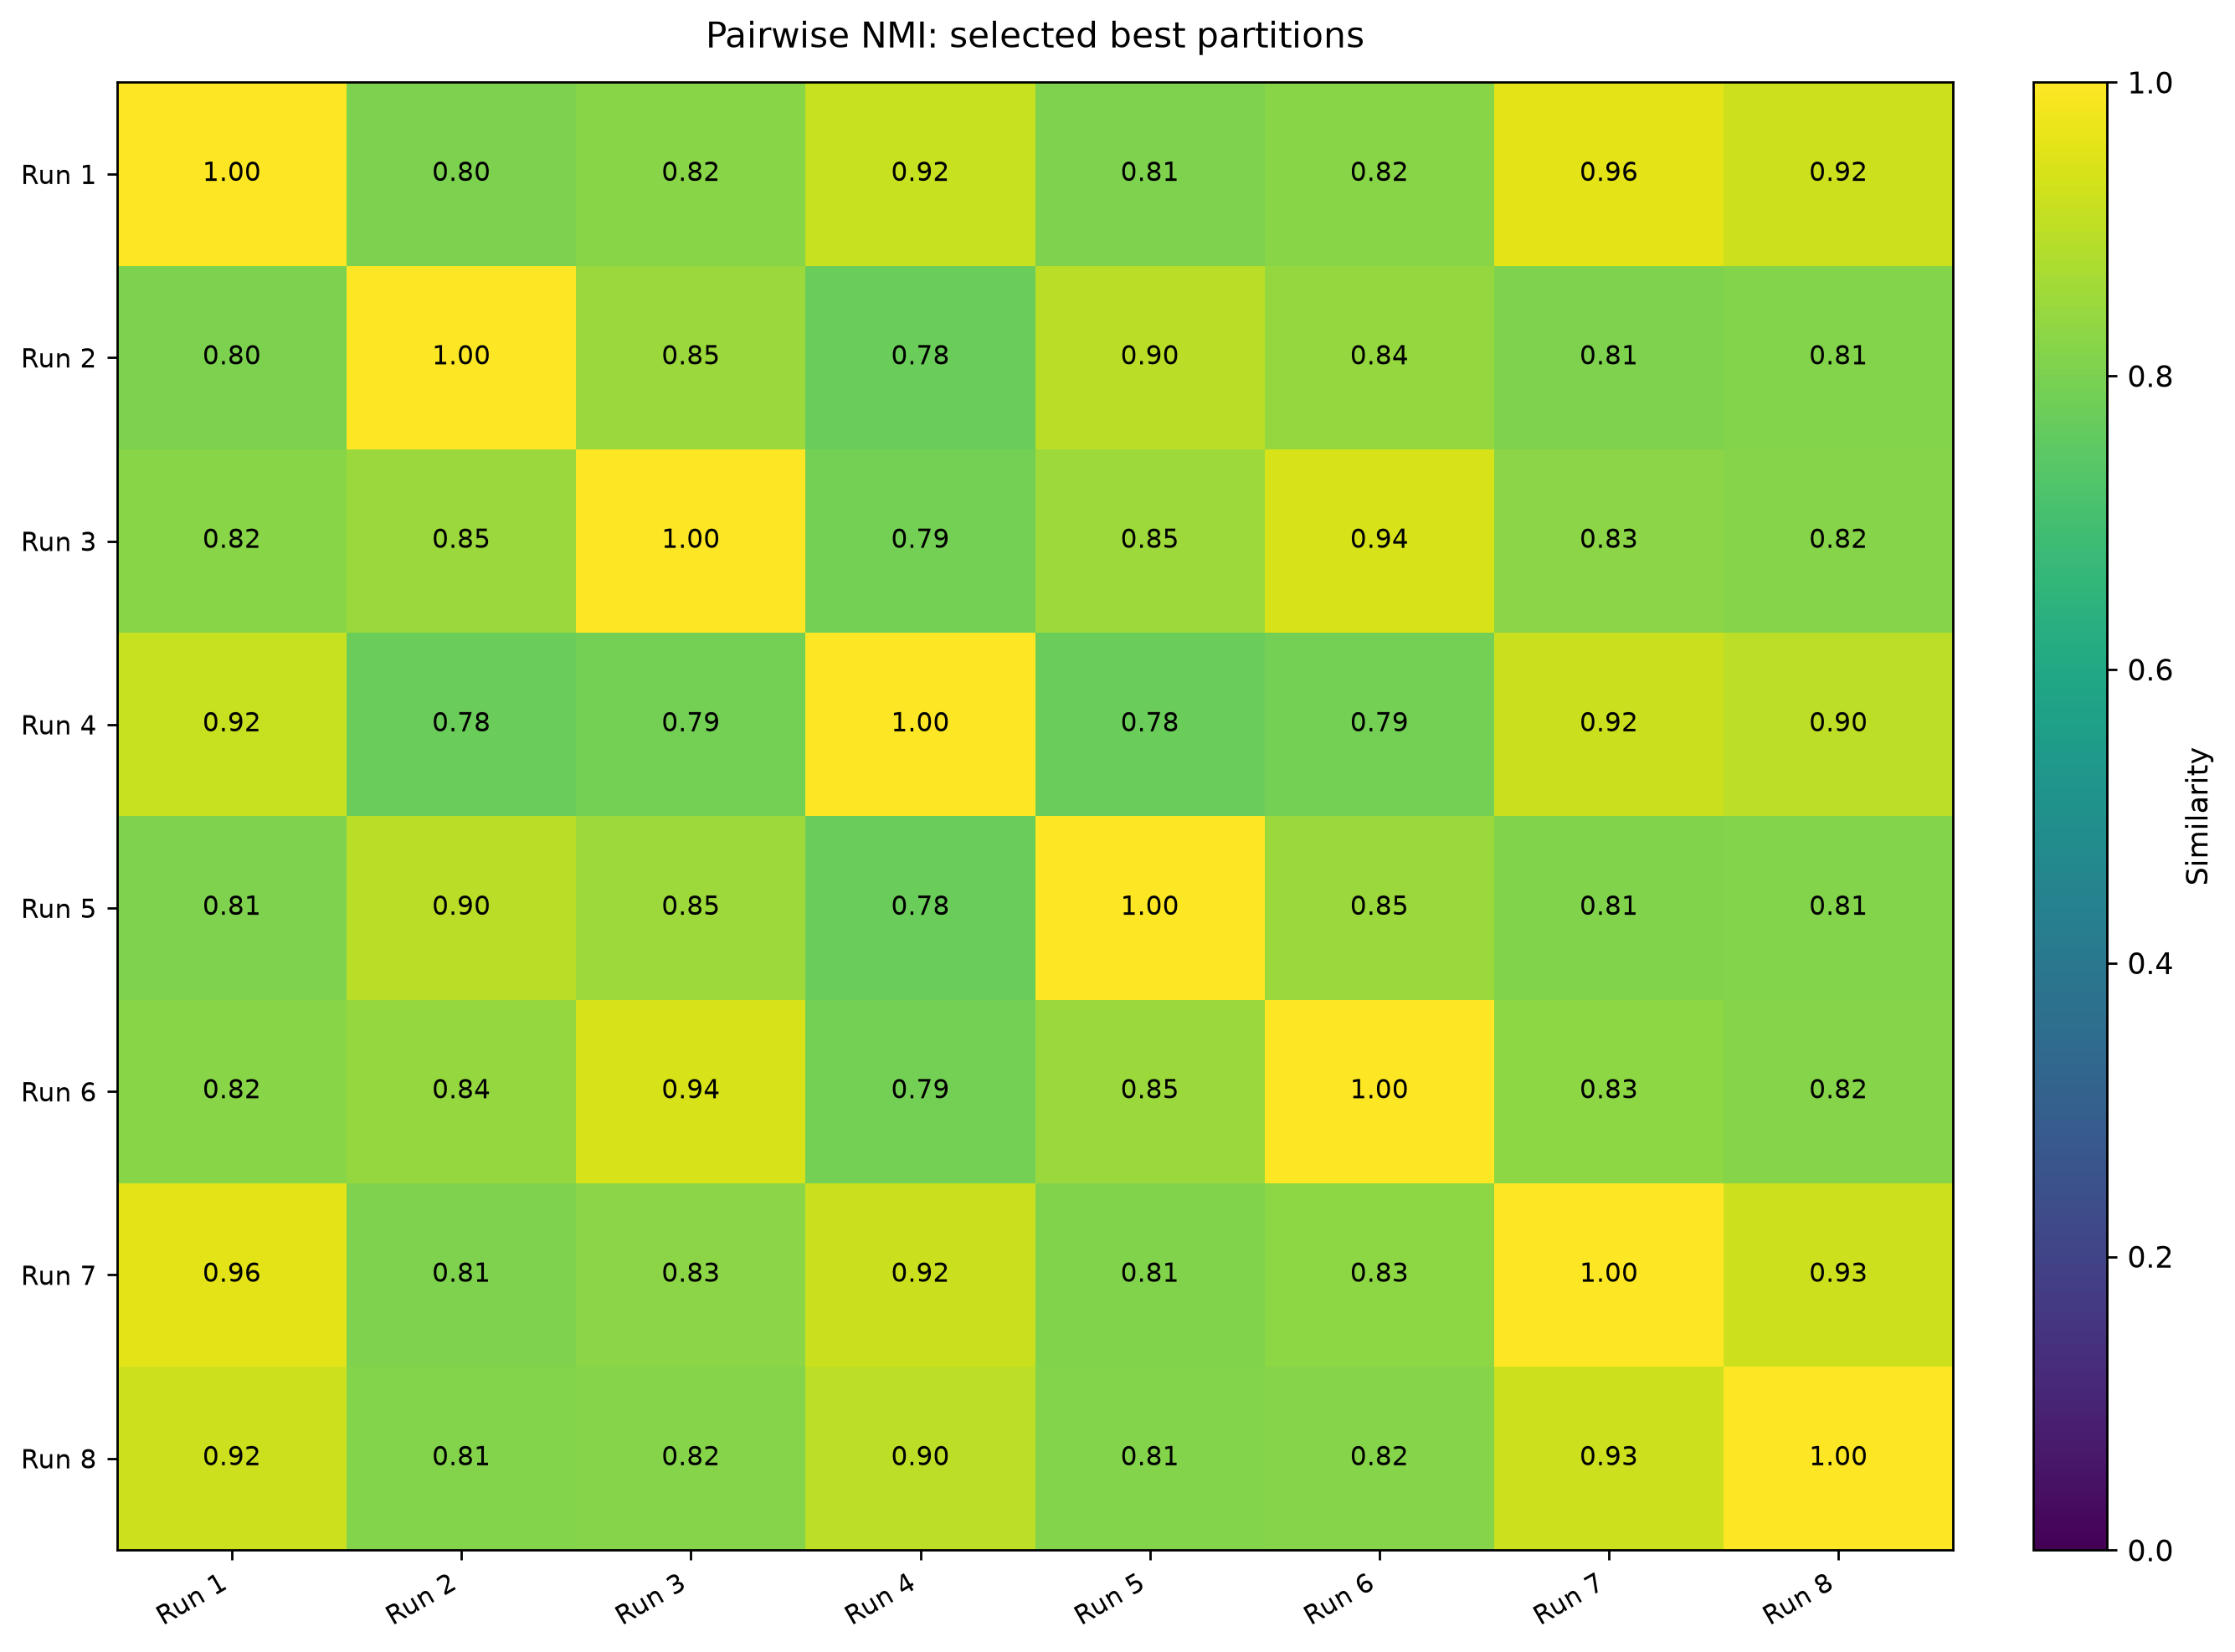

In [17]:
figures = [
    "new_fig_final_best_ari_heatmap.png",
    "new_fig_final_best_nmi_heatmap.png",
]

for filename in figures:
    path = batch_a_analysis_dir / filename
    print(filename)
    display(Image(filename=str(path)))

The selected partitions showed varying levels of agreement across runs. ARI ranged from approximately 0.55 to 0.98, while NMI ranged from 0.78 to 0.96 for distinct run pairs. Some runs produced highly similar partitions (e.g., Runs 1 and 7), whereas others showed lower agreement (e.g., Runs 4 and 5). This suggests that the agent's selected clustering outcomes were not fully consistent across runs.